# AValidate · Vision Experiment: Pretraining Ablation
### Training From Scratch (--no-pretrained)

Ablation study evaluating MobileNet-V3 initialized with random weights instead of ImageNet pretraining, trained with a slightly higher learning rate (1e-3).

---
**Hypothesis:** Quantifies the exact gain provided by ImageNet transfer learning. Training from scratch will converge slower and yield a lower final Macro-F1.

- **Run ID:** `mobilenet_scratch_v1`
- **Backbone:** `mobilenet_v3_small`
- **Epochs:** `15` | **Batch Size:** `8` | **Learning Rate:** `1e-3`
- **Loss Weighting:** `sqrt` | **Extra Flags:** `--no-pretrained`
- **Artifacts Directory:** `_local/drive/artifacts/vision_baseline/mobilenet_scratch_v1/`
- **Embeddings Directory:** `_local/drive/embeddings/mobilenet_scratch_v1/`
---


## 0 · Environment & Hardware Check
Detects local Intel Arc 140V XPU GPU or CPU compute.


In [1]:
import os, sys
import torch

# Force unbuffered streaming output for subprocesses
os.environ["PYTHONUNBUFFERED"] = "1"

# Ensure notebook runs from repository root
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
os.chdir(REPO_ROOT)
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from vision import config as C

print(f"Working directory: {REPO_ROOT}")
print(f"PyTorch version:   {torch.__version__}")

has_xpu = hasattr(torch, 'xpu') and torch.xpu.is_available()
has_cuda = torch.cuda.is_available()
if has_cuda:
    device_desc = f"NVIDIA CUDA GPU ({torch.cuda.get_device_name(0)})"
elif has_xpu:
    device_desc = f"Intel Arc XPU GPU: {torch.xpu.get_device_name(0)}"
else:
    device_desc = f"CPU ({torch.get_num_threads()} threads)"

print(f"Active compute:    {device_desc}")
print(f"Artifacts root:    {C.ARTIFACT_DIR}")
print(f"Embeddings root:   {C.EMBED_DIR}")


Working directory: e:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence
PyTorch version:   2.14.1+xpu
Active compute:    Intel Arc XPU GPU: Intel(R) Arc(TM) 140V GPU (16GB)
Artifacts root:    E:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence\_local\drive\artifacts\vision_baseline
Embeddings root:   E:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence\_local\drive\embeddings


## 1 · Weights & Biases Experiment Tracking
Reads API credentials safely from `.env` and logs to `GC2-AValidate/avalidate`.


In [2]:
from pathlib import Path

env_file = Path(REPO_ROOT) / '.env'
if env_file.exists():
    for line in env_file.read_text(encoding='utf-8').splitlines():
        if '=' in line and not line.strip().startswith('#'):
            k, v = line.strip().split('=', 1)
            os.environ[k.strip()] = v.strip()

WANDB_ENTITY = os.environ.get('WANDB_ENTITY', 'GC2-AValidate')
WANDB_PROJECT = os.environ.get('WANDB_PROJECT', 'avalidate')
api_key = os.environ.get('WANDB_API_KEY', '')

try:
    import wandb
    if api_key:
        os.environ['WANDB_ENTITY'] = WANDB_ENTITY
        os.environ['WANDB_PROJECT'] = WANDB_PROJECT
        wandb.login(key=api_key)
        WANDB = '--wandb'
        print(f"W&B is ON: logging to {WANDB_ENTITY}/{WANDB_PROJECT} (group='vision')")
    else:
        WANDB = ''
        print("W&B is OFF (WANDB_API_KEY missing)")
except Exception as e:
    WANDB = ''
    print("W&B is OFF:", e)


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: C:\Users\swara\_netrc
wandb: Currently logged in as: s3arajgupta (GC2-AValidate) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B is ON: logging to GC2-AValidate/avalidate (group='vision')


## 2 · Verify Dataset & Cached Features
Verifies that extracted video frames and label metadata exist locally.


In [3]:
!python -u -m vision.data_ave
!python -u -m vision.features


Categories: 28
Annotations: 4143 over 4097 videos (45 videos annotated more than once)
Videos found: 4097
train: 3339 samples, 0 missing videos
val  : 402 samples, 0 missing videos
test : 402 samples, 0 missing videos
Videos shared by train&val: 10
Videos shared by train&test: 8
Videos shared by val&test: 0
train: cached labels exist, skipping (use --force to overwrite)
val: cached labels exist, skipping (use --force to overwrite)
test: cached labels exist, skipping (use --force to overwrite)
norm_stats.json written to E:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence\_local\drive\cache\vision_features_v1\norm_stats.json


## 3 · Train Vision Model: `mobilenet_scratch_v1`
Trains `mobilenet_v3_small` for `15` epochs with cosine learning rate scheduling.


In [4]:
RUN_ID = 'mobilenet_scratch_v1'
BACKBONE = 'mobilenet_v3_small'
EPOCHS = 15
BATCH = 8
LR = '1e-3'
BALANCE = 'sqrt'

!python -u -m vision.train --run-id {RUN_ID} --backbone {BACKBONE} --epochs {EPOCHS} --batch {BATCH} --lr {LR} --balance {BALANCE} --no-pretrained --workers 0 {WANDB}


device=xpu backbone=mobilenet_v3_small train=3339 val=402 params=1,237,309
ep 01 loss 3.195 | val sec-acc 0.069 sec-F1 0.010 clip-acc 0.045 clip-F1 0.003 | 272s
ep 02 loss 3.004 | val sec-acc 0.149 sec-F1 0.079 clip-acc 0.142 clip-F1 0.080 | 227s
ep 03 loss 2.895 | val sec-acc 0.150 sec-F1 0.088 clip-acc 0.159 clip-F1 0.094 | 233s
ep 04 loss 2.804 | val sec-acc 0.171 sec-F1 0.123 clip-acc 0.209 clip-F1 0.167 | 241s
ep 05 loss 2.734 | val sec-acc 0.204 sec-F1 0.143 clip-acc 0.209 clip-F1 0.155 | 234s
ep 06 loss 2.677 | val sec-acc 0.226 sec-F1 0.165 clip-acc 0.236 clip-F1 0.168 | 225s
ep 07 loss 2.589 | val sec-acc 0.210 sec-F1 0.161 clip-acc 0.221 clip-F1 0.167 | 227s
ep 08 loss 2.517 | val sec-acc 0.243 sec-F1 0.188 clip-acc 0.259 clip-F1 0.205 | 224s
ep 09 loss 2.429 | val sec-acc 0.222 sec-F1 0.199 clip-acc 0.289 clip-F1 0.248 | 228s
ep 10 loss 2.367 | val sec-acc 0.271 sec-F1 0.234 clip-acc 0.346 clip-F1 0.292 | 212s
ep 11 loss 2.282 | val sec-acc 0.296 sec-F1 0.266 clip-acc 0.368 

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: s3arajgupta (GC2-AValidate) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: setting up run o7s86mue
wandb: Tracking run with wandb version 0.30.0
wandb: Run data is saved locally in e:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence\wandb\run-20261014_013425-o7s86mue
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run mobilenet_scratch_v1
wandb:  View project at https://wandb.ai/GC2-AValidate/avalidate
wandb:  View run at https://wandb.ai/GC2-AValidate/avalidate/runs/o7s86mue

ep 01/15: 100%|██████████| 418/418 [04:14<00:00,  5.79s/it, loss=3.195]
                                                                       

val: 100%|██████████| 51/51 [00:17<00:00,  1.37it/s]
                                                    

ep 02/15: 100%|██████████| 418/418 [

## 4 · Test Set Evaluation & Confusion Matrix
Evaluates the checkpoint on the 402 test clips, saves metrics to `_local/drive/artifacts/vision_baseline/mobilenet_scratch_v1/results.json`, and renders the confusion matrix.


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: s3arajgupta (GC2-AValidate) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: setting up run o7s86mue
wandb: Tracking run with wandb version 0.30.0
wandb: Run data is saved locally in e:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence\wandb\run-20261014_022210-o7s86mue
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run mobilenet_scratch_v1
wandb:  View project at https://wandb.ai/GC2-AValidate/avalidate
wandb:  View run at https://wandb.ai/GC2-AValidate/avalidate/runs/o7s86mue
wandb: uploading summary; updating run metadata
wandb: updating run metadata
wandb: uploading requirements.txt; uploading media\images\confusion_test_16_1f082e9776d6fdbca39d.png; uploading wandb-summary.json; uploading config.yaml; uploading wandb-metadata.json
wandb: uploading requireme

{
  "val": {
    "second_accuracy": 0.3116915422885572,
    "second_macro_f1": 0.2883831383318467,
    "clip_accuracy": 0.41044776119402987,
    "clip_macro_f1": 0.3672662187311064,
    "n_clips": 402
  },
  "test": {
    "second_accuracy": 0.2942786069651741,
    "second_macro_f1": 0.2760377371713582,
    "clip_accuracy": 0.3805970149253731,
    "clip_macro_f1": 0.3490552390857295,
    "n_clips": 402
  }
}

--- EVALUATION METRICS (mobilenet_scratch_v1) ---
{
  "val": {
    "second_accuracy": 0.3116915422885572,
    "second_macro_f1": 0.2883831383318467,
    "clip_accuracy": 0.41044776119402987,
    "clip_macro_f1": 0.3672662187311064,
    "n_clips": 402
  },
  "test": {
    "second_accuracy": 0.2942786069651741,
    "second_macro_f1": 0.2760377371713582,
    "clip_accuracy": 0.3805970149253731,
    "clip_macro_f1": 0.3490552390857295,
    "n_clips": 402
  }
}


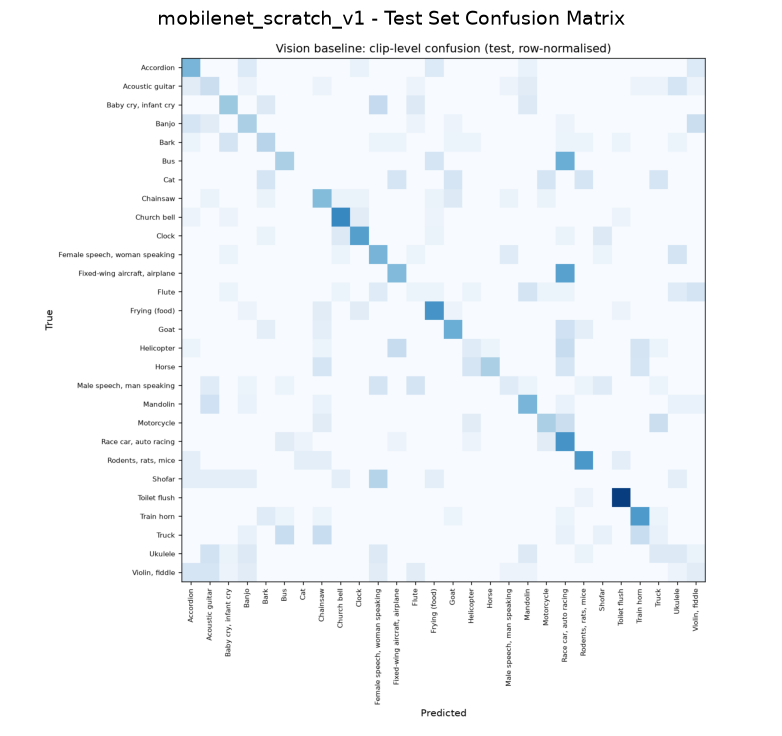

In [5]:
!python -u -m vision.evaluate --run-id {RUN_ID} --batch {BATCH} --workers 0 {WANDB}

import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from vision import config as C

run_dir = C.get_run_dir(RUN_ID)
results_file = run_dir / 'results.json'
if results_file.exists():
    print(f"\n--- EVALUATION METRICS ({RUN_ID}) ---")
    print(results_file.read_text())

confusion_file = run_dir / 'confusion_test.png'
if confusion_file.exists():
    plt.figure(figsize=(10, 9))
    img = mpimg.imread(str(confusion_file))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f'{RUN_ID} - Test Set Confusion Matrix', fontsize=14)
    plt.show()


## 5 · Export Visual Embeddings for Multimodal Fusion
Exports `(N, 10, 512)` float16 embeddings to `_local/drive/embeddings/mobilenet_scratch_v1/`.


In [6]:
!python -u -m vision.export_embeddings --run-id {RUN_ID} --batch {BATCH} --workers 0

from vision import config as C
embed_dir = C.get_embed_dir(RUN_ID)
print(f"Embeddings verified at: {embed_dir}")
if embed_dir.exists():
    for f in sorted(embed_dir.glob('*')):
        print(f"  - {f.name} ({f.stat().st_size:,} bytes)")


train: (3339, 10, 512)
val: (402, 10, 512)
test: (402, 10, 512)
Exported embeddings saved to E:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence\_local\drive\embeddings\mobilenet_scratch_v1
Embeddings verified at: E:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence\_local\drive\embeddings\mobilenet_scratch_v1
  - SOURCE.txt (43 bytes)
  - test_emb.npy (4,116,608 bytes)
  - test_ids.csv (19,057 bytes)
  - train_emb.npy (34,191,488 bytes)
  - train_ids.csv (158,199 bytes)
  - val_emb.npy (4,116,608 bytes)
  - val_ids.csv (19,065 bytes)


## 6 · Baseline Comparison
Compares `mobilenet_scratch_v1` metrics side-by-side with the default `mobilenet_10ep_v1` baseline.


In [7]:
import json
import pandas as pd
from vision import config as C

baseline_dir = C.get_run_dir('mobilenet_10ep_v1')
current_dir = C.get_run_dir(RUN_ID)

records = []
if (baseline_dir / 'results.json').exists():
    b = json.loads((baseline_dir / 'results.json').read_text())
    records.append({
        'Run ID': 'mobilenet_10ep_v1 (Baseline)',
        'Val Sec F1': f"{b['val']['second_macro_f1']*100:.1f}%",
        'Test Sec F1': f"{b['test']['second_macro_f1']*100:.1f}%",
        'Val Clip F1': f"{b['val']['clip_macro_f1']*100:.1f}%",
        'Test Clip F1': f"{b['test']['clip_macro_f1']*100:.1f}%",
        'Test Clip Acc': f"{b['test']['clip_accuracy']*100:.1f}%"
    })
if (current_dir / 'results.json').exists():
    c = json.loads((current_dir / 'results.json').read_text())
    records.append({
        'Run ID': f'{RUN_ID} (Current)',
        'Val Sec F1': f"{c['val']['second_macro_f1']*100:.1f}%",
        'Test Sec F1': f"{c['test']['second_macro_f1']*100:.1f}%",
        'Val Clip F1': f"{c['val']['clip_macro_f1']*100:.1f}%",
        'Test Clip F1': f"{c['test']['clip_macro_f1']*100:.1f}%",
        'Test Clip Acc': f"{c['test']['clip_accuracy']*100:.1f}%"
    })

if records:
    df = pd.DataFrame(records)
    display(df)


,Run ID,Val Sec F1,Test Sec F1,Val Clip F1,Test Clip F1,Test Clip Acc
0,mobilenet_10ep_v1 (Baseline),62.3%,60.9%,76.3%,71.6%,72.6%
1,mobilenet_scratch_v1 (Current),28.8%,27.6%,36.7%,34.9%,38.1%
